# LULC Semantic Segmentation from Sentinel-1

This notebook trains a deep learning model that turns **Sentinel-1 radar images** into a **land use / land cover (LULC) map** with 8 classes.

| | |
|---|---|
| **Input** | Sentinel-1 VV and VH backscatter (radar works through clouds and at night); one ablation adds static terrain (elevation, slope, height above drainage) |
| **Output** | one class per 10 m pixel: Built-up, Cropland, Trees, Shrub & grass, Bare, Water, Wetland, Snow & ice |
| **Data** | 176 sites worldwide, year 2021, 12 monthly composites per site (see `Dataset/README.md`) |
| **Labels** | pixels where ESA WorldCover and Google Dynamic World agree |
| **Model** | U-Net, a convolutional neural network (CNN), with an ImageNet-pretrained ResNet-34 encoder |

**Roadmap**

1. Setup and settings
2. Load the data
3. Explore the data
4. Input features: from radar values to model inputs
5. PCA: a compact summary of the whole year
   5b. Seasonal statistics and terrain
6. Datasets, augmentation and class balancing
7. The CNN model
8. Loss and metrics
9. Training
10. Results: training curves, test scores, confusion, seasonal effect, examples
11. Export for the prototype

**Baseline to beat** (commit `0811060`, previous dataset, no PCA): `three_month` reached test **OA 0.843, mIoU 0.559**.

**First DEV run on the current dataset** (15 epochs): `three_month_pca` val mIoU 0.656, test OA 0.834, mIoU 0.544. Val mIoU jumped by up to 7 points between epochs, so this round adds a smoothed (EMA) model, a fixed cosine learning-rate schedule, the Lovász loss, seasonal statistics channels and an optional terrain ablation (see `SESSION_CONTEXT.md`, section 8).

**Kaggle setup:** add the dataset via *Add Input*, choose *GPU T4 x1*, and turn Internet on (pretrained weights).

## Glossary: terms used in this notebook

**Data**

| Term | Meaning |
|---|---|
| Sentinel-1 (S1) | ESA radar satellites. They send microwaves and measure the echo, so they see through clouds and at night |
| backscatter, dB | the strength of the radar echo. Stored in decibels: `dB = 10·log10(power)`. -25 dB is very dark (water), 0 dB very bright (buildings) |
| VV, VH | polarisations: sent vertical, received vertical (VV) or horizontal (VH). VH comes mostly from vegetation |
| monthly composite | the average of all radar images of one month. Averaging removes most *speckle*, the grainy noise of radar |
| tile, patch | a tile is one site (1024 x 1024 px = 10.24 km). A patch is a 256 x 256 px window cut from it: one model input |
| label, ignore | the true class of each pixel. *Ignore* (-1) marks pixels where WorldCover and Dynamic World disagree; they count neither in the loss nor in the scores |
| channel | one input layer of the image. Each month gives 3 channels (VV, VH, VV-VH); PCA, statistics and terrain add more |
| standardisation | shift and scale each channel to mean 0 and standard deviation 1. Networks train better when all inputs have a similar range |
| train / val / test | train: the model learns from it. val: used to pick the best epoch and variant. test: only reported at the end. Split **by site**, so test places are never seen |
| PCA | principal component analysis: compresses a pixel's 36 yearly values into 6 numbers (section 5) |
| ablation | an experiment that adds or removes one thing to measure its effect, e.g. with vs without terrain |

**Model**

| Term | Meaning |
|---|---|
| CNN | convolutional neural network: learns small filters that slide over the image |
| encoder, decoder | the encoder shrinks the image into abstract features; the decoder grows them back to a per-pixel map |
| U-Net, skip connection | a decoder that also receives the encoder's sharp, full-resolution features, to keep fine detail |
| ResNet-34 | the encoder network (34 layers). *Pretrained* on ImageNet photos: it starts with useful edge and texture filters (transfer learning) |
| weights, parameters | the 24.5 million numbers the model learns. Saved as `<variant>_best.pt` |
| logits, softmax | the model outputs 8 scores per pixel (logits); softmax turns them into probabilities that sum to 1. The predicted class is the highest one |
| variant | one input configuration, e.g. `three_month_pca_stats` = 3 months + PCA + seasonal statistics |

**Training**

| Term | Meaning |
|---|---|
| loss | one number saying how wrong the predictions are. Training lowers it. Explained in detail in section 9 |
| cross-entropy | the main loss: `-ln(probability of the correct class)` per pixel. "Sparse" means labels are class numbers, not one-hot vectors |
| class weights | rare classes count more in the loss, so the model does not ignore them |
| Lovász-softmax | a second loss that approximates 1 - IoU, i.e. it optimises the reported score directly |
| gradient, backpropagation | for every weight, how the loss changes if the weight changes a little. Computed automatically backwards through the network |
| optimiser (AdamW) | the rule that updates the weights from the gradients. *Weight decay* gently pulls weights towards 0 against overfitting |
| learning rate (lr) | the step size of each update. Too high: unstable. Too low: slow |
| warmup, cosine schedule | lr rises over the first epoch, then falls along a cosine curve to 0 at the last epoch |
| batch, step | a batch is 16 patches processed together; one step = one weight update from one batch |
| epoch | here `SAMPLES_PER_EPOCH` = 2500 patches (about 156 steps), followed by validation |
| augmentation | random flips, rotations, crops and brightness changes, so the model sees new variations and memorises less |
| overfitting | the model learns the training sites by heart and does worse on new places: train score rises, val score does not |
| EMA | exponential moving average: a smoothed copy of the weights, averaged over the last ~3 epochs. Used for val, test and saving |
| early stopping, patience | stop when val mIoU has not improved for `PATIENCE` epochs and keep the best epoch's weights |
| mixed precision (AMP) | most maths in 16-bit floats: about 2x faster on the T4 with the same results |
| seed, run-to-run noise | the seed fixes the random numbers, but GPU maths is not fully deterministic. Two identical runs differed by 0.02-0.06 test mIoU, so smaller differences are noise |
| DEV / FINAL | DEV: short runs to compare ideas. FINAL: full-length runs for the report |

**Scores**

| Term | Meaning |
|---|---|
| confusion matrix | counts of (true class, predicted class) for all labelled pixels. Every score below comes from it |
| OA | overall accuracy: share of pixels right. Dominated by the biggest class (built-up) |
| IoU | intersection over union, per class: correct / (correct + false alarms + misses). 1 = perfect, 0 = never right |
| mIoU | the mean IoU over the 8 classes, each class counts the same. **The main score** |
| F1 | per class, the balance of precision (how many predictions are right) and recall (how many true pixels were found) |
| model card | `model_card.json`: everything the prototype needs to feed the model exactly like in training |

## 1. Setup and settings

All the settings you might want to change are in the next code cell.

- `DEV = True` is the **quick experiment mode** (about 30 min). It trains the three newest variants for 15 epochs. Use it to try ideas.
- `DEV = False` is the **final run** for the report: all variants, up to 60 epochs.
- Validation always uses all 12 months: with only 3 months the val score was too noisy to compare variants. In DEV mode it runs every 2nd epoch (`VAL_EVERY`) to save time.
- `RUN_NAME` is the results folder, `Weights/<RUN_NAME>/`. Give every run a new name; an existing folder is never overwritten.

In [1]:
DEV = True
RUN_NAME = "Test_4"

ALL_VARIANTS = {
    "single_month":                  dict(n_months=1, pca=False, stats=False, terrain=False),
    "three_month":                   dict(n_months=3, pca=False, stats=False, terrain=False),
    "three_month_pca":               dict(n_months=3, pca=True,  stats=False, terrain=False),
    "three_month_pca_stats":         dict(n_months=3, pca=True,  stats=True,  terrain=False),
    "three_month_pca_stats_terrain": dict(n_months=3, pca=True,  stats=True,  terrain=True),
}

if DEV:
    RUN = ["three_month_pca", "three_month_pca_stats", "three_month_pca_stats_terrain"]
    MAX_EPOCHS = 15
else:
    RUN = list(ALL_VARIANTS)
    MAX_EPOCHS = 60

VAL_MONTHS = list(range(12))
VAL_EVERY = 2 if DEV else 1
PATIENCE = 15
BATCH = 64
SAMPLES_PER_EPOCH = 2500
LEARNING_RATE = 6e-4
WARMUP_EPOCHS = 1
EMA_DECAY = 0.99
LOVASZ_WEIGHT = 0.5
LOVASZ_SAMPLE = 0.25
N_PCA = 6
CROP_JITTER = 128
NUM_WORKERS = 4
SEED = 42
VARIANTS = {name: ALL_VARIANTS[name] for name in RUN}
print("mode:", "DEV (quick)" if DEV else "FINAL", "| variants:", RUN, "| max epochs:", MAX_EPOCHS)

mode: DEV (quick) | variants: ['three_month_pca', 'three_month_pca_stats', 'three_month_pca_stats_terrain'] | max epochs: 15


In [2]:
import subprocess, sys
try:
    import rasterio
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
    import rasterio

import json, math, shutil, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

# DataLoader workers hand batches over through shared memory (/dev/shm). Docker containers often
# give it only 64 MB, which kills the workers with "Bus error"; then load in the main process.
if Path("/dev/shm").exists() and shutil.disk_usage("/dev/shm").total < 1e9:
    NUM_WORKERS = 0
    print("small /dev/shm: data loading runs in the main process (NUM_WORKERS = 0)")
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| rasterio", rasterio.__version__)

DATA_DIRS = [Path("../input"), Path("Dataset"), Path("../Dataset")]
OUT = Path("Weights") / RUN_NAME
if OUT.exists() and any(OUT.iterdir()):
    OUT = OUT.with_name(f"{RUN_NAME}_{time.strftime('%Y%m%d_%H%M%S')}")
    print(f"Weights/{RUN_NAME} already has files, saving to {OUT} instead")


def find_data_root():
    roots = [hit.parent.parent for base in DATA_DIRS if base.exists() for hit in base.rglob("train_patches.csv")]
    if not roots:
        raise FileNotFoundError("Dataset not found: attach the dataset with folders s1/, labels/, patches/")
    for root in roots:
        print("found dataset:", root, "| terrain/:", (root / "terrain").exists())
    # several attached versions: take the newest one, which has terrain/
    return max(roots, key=lambda r: (r / "terrain").exists())


DATA = find_data_root()
OUT.mkdir(parents=True, exist_ok=True)
print("data:", DATA, "| output:", OUT.resolve())

small /dev/shm: data loading runs in the main process (NUM_WORKERS = 0)
device: cuda NVIDIA RTX A6000
torch 2.9.1+cu128 | torchvision 0.24.1+cu128 | rasterio 1.4.4
found dataset: Dataset/Dataset | terrain/: True
data: Dataset/Dataset | output: /home/jovyan/vault/LULC-semantic-Model/Weights/Test_4


### Dataset constants

- **Radar values** are stored as uint8 codes to keep the dataset small: `dB = code * 0.2 - 35`. Code 0 means no data.
- **Labels:** 0 means *ignore* (the two label maps disagree). Classes 1-8 become indices 0-7 for training, and ignore becomes -1.

In [3]:
CLASS_NAMES = ["Built-up", "Cropland", "Trees", "Shrub & grass", "Bare / sparse",
               "Water", "Wetland & mangrove", "Snow & ice"]
CLASS_COLORS = ["#e31a1c", "#ffd92f", "#1a9850", "#a6d96a", "#bf812d", "#2c7fb8", "#41b6c4", "#f0f0f0"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
N_CLASSES = len(CLASS_NAMES)
IGNORE = -1
PATCH = 256
DB_MIN, DB_STEP = -35.0, 0.2

DB_LUT = (np.arange(256, dtype=np.float32) * DB_STEP + DB_MIN)
DB_LUT[0] = np.nan

CMAP = ListedColormap(["#000000"] + CLASS_COLORS)
LEGEND = [Patch(color=c, label=n) for n, c in zip(["ignore"] + CLASS_NAMES, ["#000000"] + CLASS_COLORS)]

## 2. Load the data

Each site is a 1024 x 1024 pixel tile (10.24 km) with 12 months x 2 polarisations. The patch index (`patches/<split>_patches.csv`) lists 256 x 256 windows with enough labels and valid radar data.

- **Train:** the **full tiles** stay in memory, so training can cut patches at random positions around the indexed windows (more variety than fixed patches).
- **Val and test:** the fixed indexed patches, so scores are comparable between runs.

The splits are **by site**: a test city or landscape is never seen during training.

In [4]:
SPLITS = ["train", "val", "test"]
index = {s: pd.read_csv(DATA / "patches" / f"{s}_patches.csv") for s in SPLITS}
for s in SPLITS:
    print(f"{s:5}: {len(index[s]):5} patches from {index[s].site.nunique():3} sites")


def read_site(site):
    with rasterio.open(DATA / "s1" / f"{site}.tif") as src:
        s1 = src.read().reshape(12, 2, src.height, src.width)
    with rasterio.open(DATA / "labels" / f"{site}.tif") as src:
        label = src.read(1).astype(np.int16) - 1
    return s1, label


HAS_TERRAIN = (DATA / "terrain").exists()


def read_terrain(site, size):
    path = DATA / "terrain" / f"{site}.tif"
    if not path.exists():
        return np.zeros((3, size, size), dtype=np.int16)
    with rasterio.open(path) as src:
        return src.read()


TILE_X, TILE_Y, TILE_T = {}, {}, {}
X, Y, T = {}, {}, {}
t0 = time.time()
for s in SPLITS:
    df = index[s]
    if s != "train":
        X[s] = np.empty((len(df), 12, 2, PATCH, PATCH), dtype=np.uint8)
        Y[s] = np.empty((len(df), PATCH, PATCH), dtype=np.int16)
        T[s] = np.empty((len(df), 3, PATCH, PATCH), dtype=np.int16)
    for site, rows in df.groupby("site"):
        s1, label = read_site(site)
        terrain = read_terrain(site, label.shape[0])
        if s == "train":
            TILE_X[site], TILE_Y[site], TILE_T[site] = s1, label, terrain
            continue
        for i, r, c in zip(rows.index, rows.row, rows.col):
            X[s][i] = s1[:, :, r:r + PATCH, c:c + PATCH]
            Y[s][i] = label[r:r + PATCH, c:c + PATCH]
            T[s][i] = terrain[:, r:r + PATCH, c:c + PATCH]

TRAIN_ORIGINS = list(zip(index["train"].site, index["train"].row, index["train"].col))


def train_window(i, dr=0, dc=0):
    site, r, c = TRAIN_ORIGINS[i]
    size = TILE_Y[site].shape[0]
    return site, int(np.clip(r + dr, 0, size - PATCH)), int(np.clip(c + dc, 0, size - PATCH))


def train_patch(i, dr=0, dc=0):
    site, r, c = train_window(i, dr, dc)
    return TILE_X[site][:, :, r:r + PATCH, c:c + PATCH], TILE_Y[site][r:r + PATCH, c:c + PATCH]


Y["train"] = np.stack([train_patch(i)[1] for i in range(len(TRAIN_ORIGINS))])
gb = (sum(t.nbytes for t in TILE_X.values()) + sum(x.nbytes for x in X.values())) / 1e9
print(f"loaded in {time.time() - t0:.0f}s, {gb:.2f} GB of radar data in memory")
if not HAS_TERRAIN:
    for name in [n for n, v in VARIANTS.items() if v["terrain"]]:
        del VARIANTS[name]
    print("no terrain/ folder in the dataset: terrain variants skipped")

train:  1958 patches from 134 sites
val  :   327 patches from  22 sites
test :   302 patches from  20 sites
loaded in 20s, 4.36 GB of radar data in memory


## 3. Explore the data

**Class distribution.** The share of each class among labelled pixels. Built-up is the largest class because the prototype targets cities. Rare classes need extra care during training (section 6).

,train %,val %,test %
Built-up,30.8,35.0,54.2
Cropland,11.3,10.5,4.9
Trees,20.3,12.8,11.6
Shrub & grass,9.5,11.1,7.7
Bare / sparse,8.1,9.6,8.2
Water,8.0,13.7,5.0
Wetland & mangrove,5.4,4.7,6.2
Snow & ice,6.5,2.6,2.3


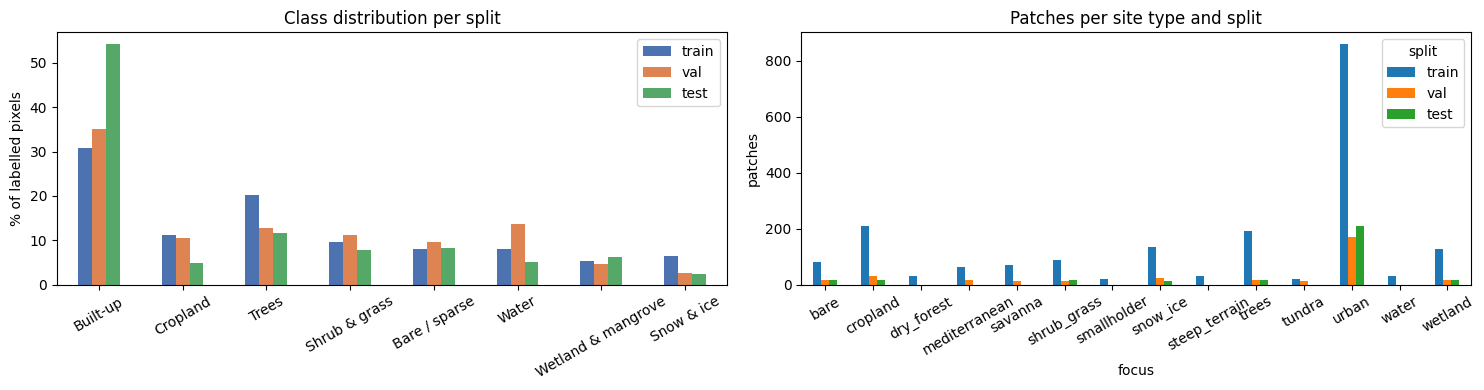

In [5]:
counts = {s: np.bincount(Y[s][Y[s] >= 0].ravel(), minlength=N_CLASSES) for s in SPLITS}
dist = pd.DataFrame({s: counts[s] / counts[s].sum() * 100 for s in SPLITS}, index=CLASS_NAMES).round(1)
display(dist.rename(columns=lambda s: f"{s} %"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dist.plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_ylabel("% of labelled pixels")
axes[0].set_title("Class distribution per split")
axes[0].tick_params(axis="x", rotation=30)
all_patches = pd.concat([index[s].assign(split=s) for s in SPLITS], ignore_index=True)
pd.crosstab(all_patches.focus, all_patches.split)[SPLITS].plot.bar(ax=axes[1])
axes[1].set_ylabel("patches")
axes[1].set_title("Patches per site type and split")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**What the radar sees.** The false-colour images show R = VV, G = VH, B = VV - VH.

- Cities are bright: walls and the ground form corner reflectors (double bounce).
- Forests are green: leaves and branches scatter the signal in all directions, which raises VH (volume scattering).
- Water and smooth sand are dark: the surface reflects the signal away from the satellite.
- January vs July shows the **seasonal change**: snow, crop growth and wet soil all change the backscatter, while the annual label stays the same.

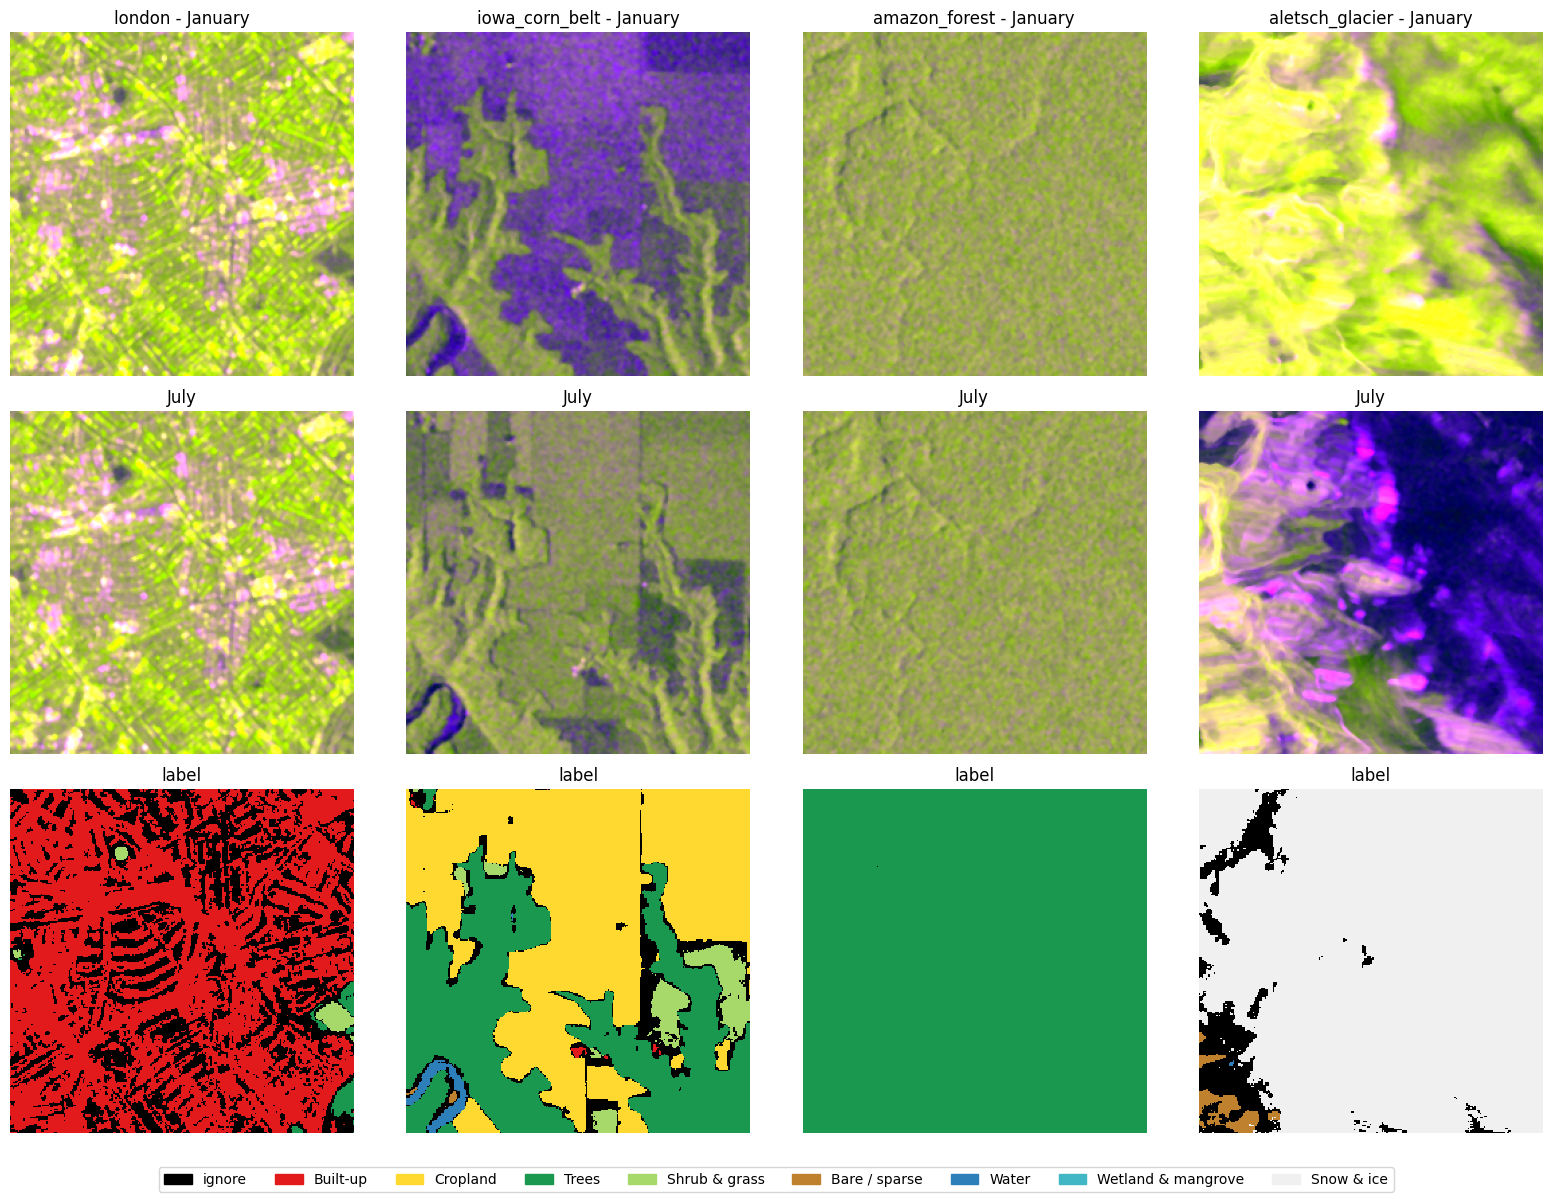

In [6]:
def false_colour(codes_2hw):
    vv, vh = DB_LUT[codes_2hw[0]], DB_LUT[codes_2hw[1]]
    rgb = np.stack([vv, vh, vv - vh], -1)
    for b, (lo, hi) in enumerate([(-20, 0), (-27, -7), (2, 15)]):
        rgb[..., b] = np.clip((rgb[..., b] - lo) / (hi - lo), 0, 1)
    return np.nan_to_num(rgb)


examples = [index["train"][index["train"].focus == f].index[0] for f in ["urban", "cropland", "trees", "snow_ice"]]
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for j, i in enumerate(examples):
    x, y = train_patch(i)
    axes[0, j].imshow(false_colour(x[0]))
    axes[0, j].set_title(f"{index['train'].site[i]} - January")
    axes[1, j].imshow(false_colour(x[6]))
    axes[1, j].set_title("July")
    axes[2, j].imshow(y + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[2, j].set_title("label")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=9)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 4. Input features: from radar values to model inputs

Each month gives **three channels**:

| Channel | Meaning |
|---|---|
| VV (dB) | co-polarised backscatter: strong for buildings and rough surfaces |
| VH (dB) | cross-polarised backscatter: strong for vegetation (volume scattering) |
| VV - VH (dB) | the ratio of the two: separates vegetation from bare surfaces and buildings |

**Standardisation.** Each channel is shifted and scaled to mean 0 and standard deviation 1, using statistics from the **train split only** (no information leaks from val/test). Missing pixels become 0, which is the channel mean.

**Month window.** The `three_month` variants see the target month plus the two months before it. The window **wraps around the year**: January uses November, December and January. The previous run repeated January instead, so the January map had no history and scored worst. The label is annual, so using December 2021 as "the month before January" is valid for training. The prototype fetches the real previous months.

In [7]:
def standardise(f, mean, std):
    return np.nan_to_num((f - mean[None, :, None, None]) / std[None, :, None, None], nan=0.0)


def window_months(month, n_months):
    return [(month - j) % 12 for j in range(n_months - 1, -1, -1)]


def month_features(codes, months):
    db = DB_LUT[codes[months]]
    vv, vh = db[:, 0], db[:, 1]
    f = standardise(np.stack([vv, vh, vv - vh], 1), CH_MEAN, CH_STD)
    return f.reshape(-1, *codes.shape[-2:]).astype(np.float32)


sample = DB_LUT[np.stack([train_patch(i)[0][:, :, ::4, ::4] for i in range(0, len(TRAIN_ORIGINS), 4)])]
feats = np.stack([sample[:, :, 0], sample[:, :, 1], sample[:, :, 0] - sample[:, :, 1]], 0).reshape(3, -1)
CH_MEAN = np.nanmean(feats, axis=1).astype(np.float32)
CH_STD = np.nanstd(feats, axis=1).astype(np.float32)
del sample, feats
print("channel mean (VV, VH, VV-VH):", CH_MEAN.round(3))
print("channel std  (VV, VH, VV-VH):", CH_STD.round(3))

channel mean (VV, VH, VV-VH): [ -9.189 -16.591   7.402]
channel std  (VV, VH, VV-VH): [5.639 5.736 2.728]


## 5. PCA: a compact summary of the whole year

**What PCA does.** Principal Component Analysis finds the directions in which the data varies most, and re-expresses every sample along those directions. The first component captures the most variance, the second the most of what is left, and so on. Keeping only the first few components gives a **compact summary** with little information lost.

**How it is used here.** Every pixel has a 36-value time series: 12 months x 3 channels. Many of these values are redundant, because a forest looks similar in May and June. PCA compresses the 36 values into `N_PCA = 6` components:

- the first component is roughly the **average brightness** over the year (city vs forest vs water);
- the next ones describe **how the pixel changes over the year** (crops grow and are harvested, snow comes and goes, wetlands flood).

The `three_month_pca` variant adds these 6 components to its 9 monthly channels as **annual context**. This should help the classes that SAR confuses in a single month, such as cropland vs trees and water vs snow.

**Why not replace the inputs with PCA?** The model only has 3 channels per month, so there is nothing to reduce there. The CNN also learns its own, better features from the pixels. PCA helps as a cheap summary of the **time** dimension, not of the channels.

**Trade-off for the prototype.** The annual context is the same for all 12 monthly maps. This makes the maps more stable from month to month, which reduces fake change caused by seasons, but it can also hide real change that happens within the year.

The PCA is fitted on train pixels only. The component maps are computed **once** per tile in section 5b.

variance explained by the first 6 components: 92.0%


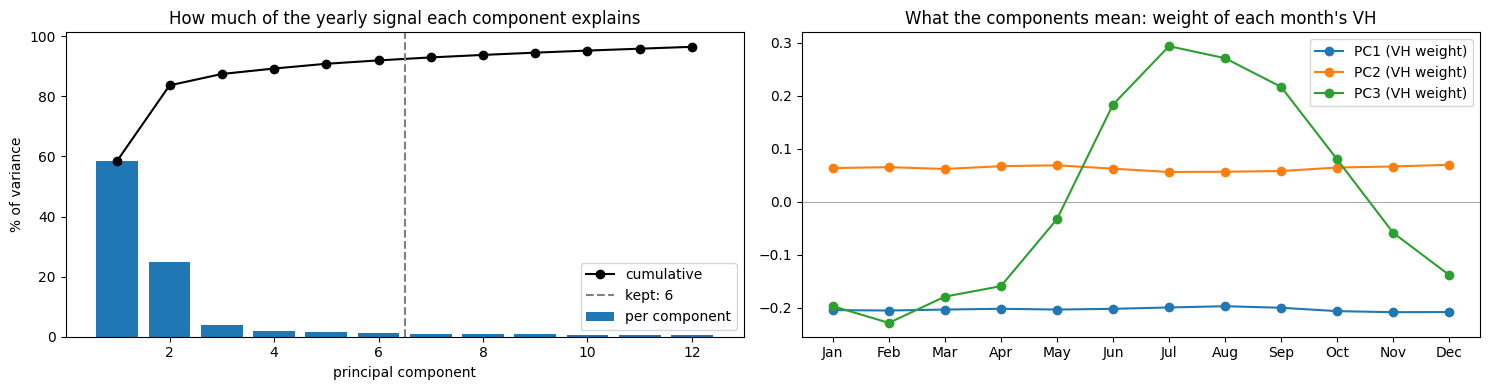

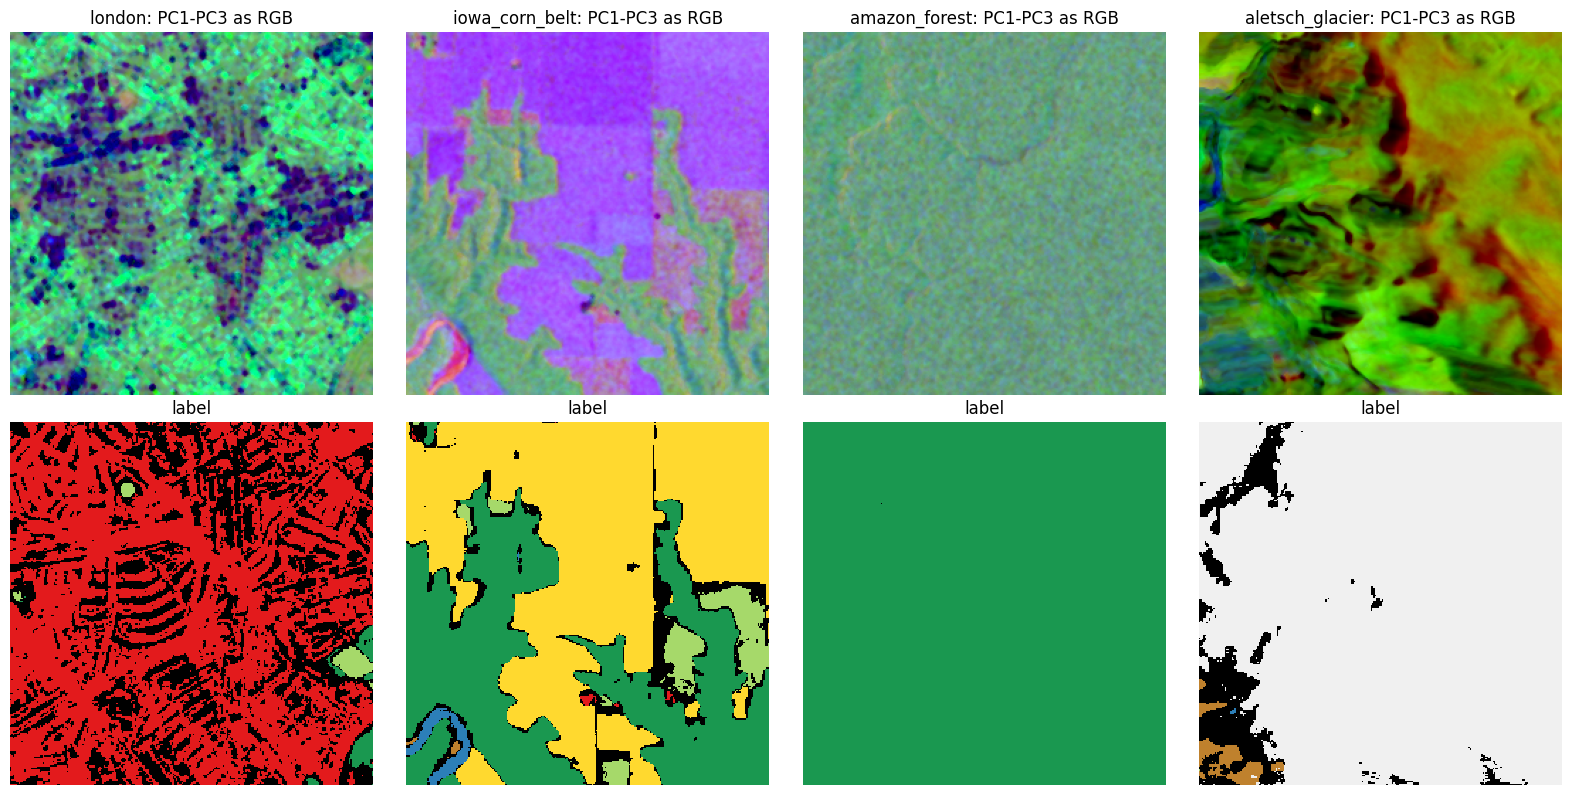

In [8]:
def annual_features(codes):
    return month_features(codes, list(range(12))).reshape(36, -1)


pixels = np.concatenate([annual_features(train_patch(i)[0][:, :, ::8, ::8])
                         for i in range(0, len(TRAIN_ORIGINS), 2)], axis=1)
PCA_MEAN = pixels.mean(1).astype(np.float32)
eigval, eigvec = np.linalg.eigh(np.cov(pixels - PCA_MEAN[:, None]))
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
PCA_W = (eigvec[:, :N_PCA].T / np.sqrt(eigval[:N_PCA, None])).astype(np.float32)
explained = eigval / eigval.sum()
del pixels


def pca_features(codes):
    pcs = PCA_W @ (annual_features(codes) - PCA_MEAN[:, None])
    return pcs.reshape(N_PCA, *codes.shape[-2:]).astype(np.float32)


print("variance explained by the first", N_PCA, "components:", f"{explained[:N_PCA].sum() * 100:.1f}%")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(range(1, 13), explained[:12] * 100, label="per component")
axes[0].plot(range(1, 13), np.cumsum(explained[:12]) * 100, "o-", color="black", label="cumulative")
axes[0].axvline(N_PCA + 0.5, color="grey", ls="--", label=f"kept: {N_PCA}")
axes[0].set_xlabel("principal component")
axes[0].set_ylabel("% of variance")
axes[0].set_title("How much of the yearly signal each component explains")
axes[0].legend()
loadings = eigvec[:, :3].reshape(12, 3, 3)
for k in range(3):
    axes[1].plot(MONTH_NAMES, loadings[:, 1, k], marker="o", label=f"PC{k + 1} (VH weight)")
axes[1].axhline(0, color="grey", lw=0.5)
axes[1].set_title("What the components mean: weight of each month's VH")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for j, i in enumerate(examples):
    x, y = train_patch(i)
    rgb = pca_features(x)[:3].transpose(1, 2, 0)
    axes[0, j].imshow(np.clip(rgb / 4 + 0.5, 0, 1))
    axes[0, j].set_title(f"{index['train'].site[i]}: PC1-PC3 as RGB")
    axes[1, j].imshow(y + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[1, j].set_title("label")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**How to read this.** If a few components explain most of the variance, the yearly signal is very redundant and 6 numbers summarise it well. In the RGB images, areas with the same colour behave the same way over the year; compare them with the label map below.

## 5b. Seasonal statistics and terrain

**Seasonal statistics** are 5 hand-made summaries of each pixel's 12 months. PCA finds the main patterns automatically; these channels name the ones we know matter:

| Channel | Meaning | Helps with |
|---|---|---|
| VV min, VV max | darkest and brightest month | water (always dark), snow and frozen ground (dark in winter only) |
| VH std | how much the vegetation signal varies over the year | cropland (sown, grown, harvested) vs trees (stable) |
| VH spread | 2nd brightest minus 2nd darkest month of VH; like the std, but robust to one odd month | same, less sensitive to noise |
| water months | share of months with VV below -18 dB (open water reflects the radar away) | permanent water (~1.0) vs seasonally flooded wetland (between 0 and 1) |

**Terrain** (optional, only the `..._terrain` variant) comes from elevation models, not from Sentinel-1:

| Channel | Source | Helps with |
|---|---|---|
| elevation (m) | Copernicus GLO-30 DEM | snow and ice lie high |
| slope (degrees) | from the same DEM | wetland and water are flat; steep slopes distort the radar |
| HAND (log of metres) | MERIT Hydro, height above the nearest river | wetland and floodplains lie only a few metres above a river |

Terrain is static context, not a second sensor, so the report shows it as an **ablation**: `three_month_pca_stats` (Sentinel-1 only) vs `three_month_pca_stats_terrain` (Sentinel-1 + terrain). The prototype uses the pure Sentinel-1 model unless terrain clearly helps.

All static channels (PCA, statistics, terrain) are standardised with train statistics and computed **once** per tile, then stored as float16. Computing them for every sample made an epoch 5x slower.

14 static channels precomputed in 131s (5.1 GB)
terrain: loaded


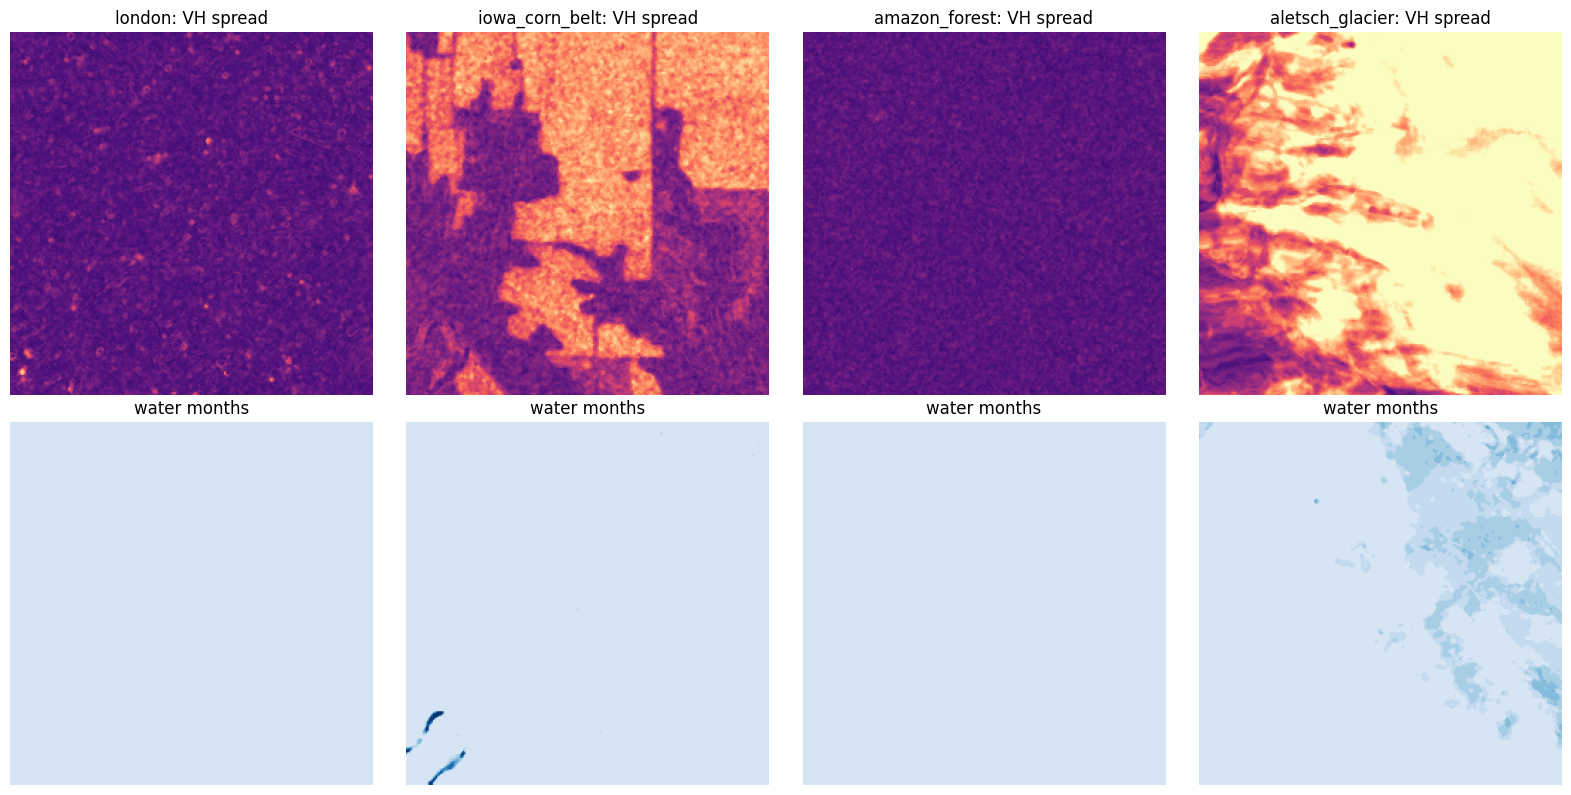

In [9]:
WATER_DB = -18.0
STAT_NAMES = ["VV min", "VV max", "VH std", "VH spread", "water months"]
TERRAIN_NAMES = ["elevation", "slope", "HAND"]
STATIC_NAMES = [f"PC{k + 1}" for k in range(N_PCA)] + STAT_NAMES + TERRAIN_NAMES
N_STATS, N_STATIC = len(STAT_NAMES), len(STATIC_NAMES)


def stats_raw(codes):
    db = DB_LUT[codes]
    vv, vh = db[:, 0], db[:, 1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        vh_sorted = np.sort(np.where(np.isnan(vh), np.nanmean(vh, 0), vh), 0)
        n_valid = np.maximum((~np.isnan(vv)).sum(0), 1)
        out = np.stack([np.nanmin(vv, 0), np.nanmax(vv, 0), np.nanstd(vh, 0),
                        vh_sorted[-2] - vh_sorted[1], (vv < WATER_DB).sum(0) / n_valid])
    return out.astype(np.float32)


def terrain_raw(t):
    t = t.astype(np.float32)
    return np.stack([t[0], t[1] / 10, np.log1p(np.clip(t[2] / 10, 0, None))])


def fit_mean_std(maps):
    flat = np.concatenate([m.reshape(m.shape[0], -1) for m in maps], 1)
    return np.nanmean(flat, 1).astype(np.float32), np.nanstd(flat, 1).astype(np.float32)


fit_ids = range(0, len(TRAIN_ORIGINS), 2)
STAT_MEAN, STAT_STD = fit_mean_std([stats_raw(train_patch(i)[0][:, :, ::8, ::8]) for i in fit_ids])
TER_MEAN, TER_STD = fit_mean_std([terrain_raw(TILE_T[TRAIN_ORIGINS[i][0]][:, ::8, ::8]) for i in fit_ids])
TER_STD = np.maximum(TER_STD, 1e-3)


def stats_features(codes):
    return standardise(stats_raw(codes)[None], STAT_MEAN, STAT_STD)[0]


def terrain_features(t):
    return standardise(terrain_raw(t)[None], TER_MEAN, TER_STD)[0]


def static_maps(codes, terrain, rows=128):
    out = np.empty((N_STATIC, *codes.shape[-2:]), dtype=np.float16)
    for r in range(0, codes.shape[-2], rows):
        c, t = codes[:, :, r:r + rows], terrain[:, r:r + rows]
        out[:, r:r + rows] = np.concatenate([pca_features(c), stats_features(c), terrain_features(t)])
    return out


t0 = time.time()
STATIC_TILE = {site: static_maps(x, TILE_T[site]) for site, x in TILE_X.items()}
STATIC_X = {s: np.stack([static_maps(x, t) for x, t in zip(X[s], T[s])]) for s in ("val", "test")}
gb = (sum(m.nbytes for m in STATIC_TILE.values()) + sum(m.nbytes for m in STATIC_X.values())) / 1e9
print(f"{N_STATIC} static channels precomputed in {time.time() - t0:.0f}s ({gb:.1f} GB)")
print("terrain:", "loaded" if HAS_TERRAIN else "missing (zeros)")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for j, i in enumerate(examples):
    site, r, c = train_window(i)
    s = STATIC_TILE[site][:, r:r + PATCH, c:c + PATCH].astype(np.float32)
    axes[0, j].imshow(s[STATIC_NAMES.index("VH spread")], cmap="magma", vmin=-2, vmax=3)
    axes[0, j].set_title(f"{site}: VH spread")
    axes[1, j].imshow(s[STATIC_NAMES.index("water months")], cmap="Blues", vmin=-1, vmax=3)
    axes[1, j].set_title("water months")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**How to read this.** Bright *VH spread* marks pixels whose vegetation changes a lot over the year (fields); forests and cities stay dark. *Water months* is dark blue for permanent water and lighter where land is only flooded in some months.

## 6. Datasets, augmentation and class balancing

**One training item** = one patch, one random month, and the matching annual label. The model therefore learns to classify any single month, which is what the prototype needs (12 monthly maps).

**Augmentation** creates new, realistic variations of the training data. This fights **overfitting**: in the baseline, train mIoU reached 0.79 while val stayed at 0.47, so the model memorised the training sites.

| Augmentation | Why |
|---|---|
| random crop position (up to ±128 px around the indexed patch) | the model sees new pixel arrangements every epoch |
| flips and 90° rotations | land cover has no fixed orientation |
| random brightness shift (±1 dB) and noise (0.5 dB) | radar brightness varies with incidence angle, soil moisture and calibration between regions |

**Class balancing**

1. **Class weights in the loss:** `w = sqrt(median_freq / freq)`, so mistakes on rare classes cost more. The square root keeps rare classes from dominating.
2. **Patch sampler:** patches containing rare classes are drawn more often.

**Val and test** use fixed patches without augmentation. Test always uses all 12 months.

**Speed: the GPU builds the batches.** The data loader workers only cut the raw uint8 codes, the static channels and the label out of memory. The GPU then does the rest for the whole batch at once (`gpu_input`: dB lookup, brightness shift and noise, VV-VH, standardisation; `gpu_augment`: flips and rotations). Kaggle gives only 4 CPU cores, and doing this work per sample on the CPU left the GPU waiting: in the previous run an epoch took 32 s without PCA and 158 s with PCA computed on the CPU.

In [10]:
def static_index(variant):
    idx = []
    if variant["pca"]:
        idx += list(range(N_PCA))
    if variant["stats"]:
        idx += list(range(N_PCA, N_PCA + N_STATS))
    if variant["terrain"]:
        idx += list(range(N_PCA + N_STATS, N_STATIC))
    return idx


def window_codes(codes, month, variant):
    return codes[window_months(month, variant["n_months"])]


LUT_T = torch.tensor(DB_LUT, device=DEVICE)
CH_MEAN_T = torch.tensor(CH_MEAN, device=DEVICE).view(1, 1, 3, 1, 1)
CH_STD_T = torch.tensor(CH_STD, device=DEVICE).view(1, 1, 3, 1, 1)


def gpu_input(codes, static, shift_db=None):
    """uint8 codes (B, months, 2, H, W) + float16 static (B, S, H, W) -> standardised model input on the GPU.

    Same features as month_features: VV, VH, VV-VH per month (oldest first), then the static channels.
    shift_db (B,) adds the brightness shift and 0.5 dB noise augmentation.
    """
    db = LUT_T[codes.to(DEVICE, non_blocking=True).long()]
    if shift_db is not None:
        db = db + shift_db.view(-1, 1, 1, 1, 1) + 0.5 * torch.randn_like(db)
    vv, vh = db[:, :, 0], db[:, :, 1]
    f = torch.nan_to_num((torch.stack([vv, vh, vv - vh], 2) - CH_MEAN_T) / CH_STD_T, nan=0.0).flatten(1, 2)
    x = torch.cat([f, static.to(DEVICE, non_blocking=True).float()], 1)
    return x.contiguous(memory_format=torch.channels_last)


def gpu_augment(x, y):
    """Random flips and 90-degree rotations, drawn per sample."""
    for i in range(len(x)):
        dims = [d for d, flip in zip((-1, -2), torch.rand(2) < 0.5) if flip]
        xi, yi = (x[i].flip(dims), y[i].flip(dims)) if dims else (x[i], y[i])
        k = int(torch.randint(4, ()))
        x[i], y[i] = torch.rot90(xi, k, (-2, -1)), torch.rot90(yi, k, (-2, -1))
    return x, y


def input_channels(variant):
    return 3 * variant["n_months"] + len(static_index(variant))


class TrainDataset(Dataset):
    def __init__(self, variant):
        self.variant = variant

    def __len__(self):
        return len(TRAIN_ORIGINS)

    def __getitem__(self, i):
        site, r, c = train_window(i, *np.random.randint(-CROP_JITTER, CROP_JITTER + 1, 2))
        month = np.random.randint(12)
        codes = window_codes(TILE_X[site][:, :, r:r + PATCH, c:c + PATCH], month, self.variant)
        static = STATIC_TILE[site][static_index(self.variant), r:r + PATCH, c:c + PATCH]
        label = TILE_Y[site][r:r + PATCH, c:c + PATCH].astype(np.int64)
        return torch.from_numpy(codes), torch.from_numpy(static), torch.from_numpy(label), month


class EvalDataset(Dataset):
    def __init__(self, x, y, static, variant, months=range(12)):
        self.x, self.y, self.static, self.variant = x, y, static, variant
        self.items = [(i, m) for i in range(len(x)) for m in months]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, k):
        i, month = self.items[k]
        codes = window_codes(self.x[i], month, self.variant)
        static = self.static[i][static_index(self.variant)]
        return torch.from_numpy(codes), torch.from_numpy(static), torch.from_numpy(self.y[i].astype(np.int64)), month


def seed_worker(worker_id):
    np.random.seed(torch.initial_seed() % 2 ** 32)


freq = counts["train"] / counts["train"].sum()
CLASS_WEIGHTS = np.sqrt(np.median(freq) / np.clip(freq, 1e-6, None))
CLASS_WEIGHTS = (CLASS_WEIGHTS / CLASS_WEIGHTS.mean()).astype(np.float32)
display(pd.DataFrame({"train share %": (freq * 100).round(2), "loss weight": CLASS_WEIGHTS.round(2)},
                     index=CLASS_NAMES))

patch_frac = np.stack([np.bincount(y[y >= 0], minlength=N_CLASSES) / max((y >= 0).sum(), 1)
                       for y in Y["train"]])
PATCH_WEIGHTS = np.where(patch_frac >= 0.01, CLASS_WEIGHTS[None], 0).max(1)
print("patch sampling weight range:", PATCH_WEIGHTS.min().round(2), "-", PATCH_WEIGHTS.max().round(2))

,train share %,loss weight
Built-up,30.81,0.57
Cropland,11.32,0.93
Trees,20.32,0.70
Shrub & grass,9.52,1.02
Bare / sparse,8.08,1.10
Water,7.99,1.11
Wetland & mangrove,5.43,1.35
Snow & ice,6.53,1.23


patch sampling weight range: 0.57 - 1.35


## 7. The CNN model: U-Net with a ResNet-34 encoder

**Why a CNN.** A convolutional layer slides small learned filters (3 x 3 pixels) over the image. Early layers detect simple patterns such as edges and speckle texture. Deeper layers combine them into larger patterns such as street grids, field parcels or river banks. This is exactly what LULC mapping needs: the class of a pixel depends on its **neighbourhood**, not only on its own value.

**Encoder (ResNet-34, transfer learning).**
- The encoder shrinks the image step by step (1/2 ... 1/32 of the size) while learning more abstract features. At the deepest level, each feature sees about 2.5 km of context.
- It starts from weights pretrained on ImageNet photos. Edge and texture filters transfer to radar images, so training is faster and needs less data.
- The first layer is adapted to our channel count: its RGB filters are averaged and copied to every input channel, scaled by `3 / channels` to keep the same signal strength.

**Decoder (U-Net).**
- The decoder enlarges the features back to full size in 5 steps.
- **Skip connections** pass the sharp, high-resolution features from the encoder to the decoder at each step. This restores the 10 m detail needed for roads, rivers and field edges.
- A final 1 x 1 convolution gives 8 class scores per pixel.

```
input (C x 256 x 256)
  -> encoder: 128 -> 64 -> 32 -> 16 -> 8 px   (more channels, more context)
  -> decoder:   8 -> 16 -> 32 -> 64 -> 128 -> 256 px   (+ skip connections)
  -> 8 class scores per pixel
```

In [11]:
class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([x, skip], 1)
        return self.conv(x)


class UNetResNet34(nn.Module):
    def __init__(self, in_ch, n_classes, pretrained=True):
        super().__init__()
        try:
            enc = torchvision.models.resnet34(weights="IMAGENET1K_V1" if pretrained else None)
        except Exception as err:
            print("pretrained weights unavailable, using random init:", err)
            enc = torchvision.models.resnet34(weights=None)
        conv1 = nn.Conv2d(in_ch, 64, 7, stride=2, padding=3, bias=False)
        with torch.no_grad():
            conv1.weight.copy_(enc.conv1.weight.mean(1, keepdim=True).repeat(1, in_ch, 1, 1) * 3 / in_ch)
        self.stem = nn.Sequential(conv1, enc.bn1, enc.relu)
        self.pool = enc.maxpool
        self.enc1, self.enc2, self.enc3, self.enc4 = enc.layer1, enc.layer2, enc.layer3, enc.layer4
        self.dec4 = UpBlock(512, 256, 256)
        self.dec3 = UpBlock(256, 128, 128)
        self.dec2 = UpBlock(128, 64, 64)
        self.dec1 = UpBlock(64, 64, 64)
        self.dec0 = UpBlock(64, 0, 32)
        self.dropout = nn.Dropout2d(0.1)
        self.head = nn.Conv2d(32, n_classes, 1)

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.enc1(self.pool(s0))
        s2 = self.enc2(s1)
        s3 = self.enc3(s2)
        s4 = self.enc4(s3)
        d = self.dec4(s4, s3)
        d = self.dec3(d, s2)
        d = self.dec2(d, s1)
        d = self.dec1(d, s0)
        d = self.dec0(d)
        return self.head(self.dropout(d))


for name, variant in ALL_VARIANTS.items():
    print(f"{name:16} input channels: {input_channels(variant)}")
m = UNetResNet34(3, N_CLASSES, pretrained=False)
print(f"parameters: {sum(p.numel() for p in m.parameters()) / 1e6:.1f} M")
print("output shape:", tuple(m(torch.zeros(1, 3, PATCH, PATCH)).shape))
del m

single_month     input channels: 3
three_month      input channels: 9
three_month_pca  input channels: 15
three_month_pca_stats input channels: 20
three_month_pca_stats_terrain input channels: 23
parameters: 24.5 M
output shape: (1, 8, 256, 256)


## 8. Loss and metrics

**Loss = weighted sparse categorical cross-entropy + 0.5 x Lovász-softmax**

- *Sparse categorical cross-entropy* compares the predicted class probabilities with the true class index of each pixel ("sparse" = integer labels, not one-hot vectors). It is PyTorch's `CrossEntropyLoss`, the same as Keras' `SparseCategoricalCrossentropy`. Ignored pixels (-1) are skipped, and the class weights from section 6 are applied.
- *Lovász-softmax* (Berman et al., CVPR 2018) is a smooth version of **1 - IoU**, so the model is trained directly on the metric we report. Like Dice it treats every class equally, which helps the rare classes. It replaced Dice in this round: the DFC2025 SAR land-cover winner gained +0.29 mIoU from CE + Lovász over CE alone.
- Lovász sorts all pixel errors of each class, which is slow for 1 million pixels per batch. It is computed on a random 25 % of the pixels (`LOVASZ_SAMPLE`); the estimate of IoU stays almost the same.
- The **printed and plotted loss is the cross-entropy part only**, for train and val alike, so the two are comparable. The Lovász part still trains the model; it is just not logged.

**Metrics** (all from a confusion matrix over labelled pixels):

| Metric | Meaning | How to read it |
|---|---|---|
| **OA** (overall accuracy) | share of pixels classified correctly | inflated by the big built-up class |
| **IoU** per class | correct / (correct + false alarms + misses) | the strictest per-class score |
| **mIoU** | mean IoU over the 8 classes, each class counts equally | **the main score** |
| **F1** per class | balance of precision and recall; F1 = 2·IoU / (1 + IoU) | always higher than IoU |

In [12]:
def lovasz_grad(fg_sorted):
    total = fg_sorted.sum()
    intersection = total - fg_sorted.cumsum(0)
    union = total + (1 - fg_sorted).cumsum(0)
    jaccard = 1 - intersection / union
    jaccard[1:] = jaccard[1:] - jaccard[:-1]
    return jaccard


def lovasz_softmax(probs, target, sample=1.0):
    probs = probs.permute(0, 2, 3, 1).reshape(-1, probs.shape[1])
    target = target.reshape(-1)
    valid = (target != IGNORE) & (torch.rand(len(target), device=target.device) < sample)
    probs, target = probs[valid], target[valid]
    losses = []
    for c in range(probs.shape[1]):
        fg = (target == c).float()
        if fg.sum() == 0:
            continue
        errors, order = (fg - probs[:, c]).abs().sort(descending=True)
        losses.append(torch.dot(errors, lovasz_grad(fg[order])))
    return torch.stack(losses).mean() if losses else probs.sum() * 0


class CELovaszLoss(nn.Module):
    def __init__(self, class_weights, lovasz_weight=LOVASZ_WEIGHT):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, ignore_index=IGNORE)
        self.lovasz_weight = lovasz_weight

    def forward(self, logits, target):
        """Returns (total loss to optimise, cross-entropy part for logging)."""
        ce = self.ce(logits, target)
        lovasz = lovasz_softmax(logits.float().softmax(1), target, LOVASZ_SAMPLE)
        return ce + self.lovasz_weight * lovasz, ce


def update_confusion(conf, logits, target):
    pred = logits.argmax(1)
    valid = target != IGNORE
    conf += torch.bincount(target[valid] * N_CLASSES + pred[valid],
                           minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
    return conf


def metrics_from_confusion(conf):
    conf = conf.double()
    tp = conf.diag()
    fp, fn = conf.sum(0) - tp, conf.sum(1) - tp
    iou = tp / (tp + fp + fn).clamp(min=1)
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)
    present = conf.sum(1) > 0
    return {"OA": (tp.sum() / conf.sum()).item(),
            "mIoU": iou[present].mean().item(),
            "IoU": iou.cpu().numpy(), "F1": f1.cpu().numpy()}


criterion = CELovaszLoss(torch.tensor(CLASS_WEIGHTS, device=DEVICE))

## 9. Training

**How one variant is trained**

- **Optimiser:** AdamW (learning rate 3e-4, weight decay 1e-4) with mixed precision (faster on the GPU).
- **One epoch** = `SAMPLES_PER_EPOCH` patches drawn by the class-aware sampler, each with a random month and augmentation. The epoch length does not grow with the dataset, so epoch times stay comparable.
- **Learning-rate schedule: warmup + cosine.** The learning rate rises linearly during the first epoch (the new first layer and decoder start random, so big steps at the start could damage the pretrained encoder), then follows a cosine curve down to 0 at `MAX_EPOCHS`. The schedule is fixed, so every variant gets exactly the same training and the comparison is fair. The previous run halved the rate when val stalled, which depended on noisy val scores.
- **EMA (exponential moving average) of the weights.** After every step, a second copy of the model is updated as `ema = 0.998 * ema + 0.002 * weights`, a running average over roughly the last 500 steps (3 epochs). Single steps on noisy labels push the weights back and forth; the average sits in the middle and is more stable. **Validation, the saved checkpoint and the test use the EMA model.** In the previous run val mIoU jumped by up to 7 points between epochs.
- **Early stopping:** training stops when the EMA val mIoU has not improved for `PATIENCE` epochs. The best EMA checkpoint is restored and saved.

**Speed settings:** cuDNN autotuning (`cudnn.benchmark`) picks the fastest convolution algorithm for our input size once at the start, and the *channels-last* memory layout lets the T4's tensor cores work on mixed-precision convolutions directly.

### How to read the training log

One line per epoch, for example:

```
epoch  7 | train loss 0.929 mIoU 0.635 | val loss 1.026 OA 0.802 mIoU 0.585 | lr 2.6e-04 | 41s *
```

| Part | Meaning |
|---|---|
| `train loss` | average weighted cross-entropy over this epoch's training batches (with augmentation, raw model) |
| `train mIoU` | mIoU on those same training batches. Higher than val is normal; a growing gap means overfitting |
| `val loss` | cross-entropy of the EMA model on the validation sites (unseen during training) |
| `val OA`, `val mIoU` | accuracy and mean IoU on the validation sites. **val mIoU decides which weights are kept** |
| `nan` | no validation this epoch (DEV validates every 2nd epoch) |
| `lr` | the learning rate at the end of the epoch (warmup, then cosine decay) |
| `41s` | time for the epoch, including validation |
| `*` | new best val mIoU: these weights were saved |

**What the loss number means.** Cross-entropy is `-ln(p)`, where `p` is the probability the model gave to the correct class, averaged over all labelled pixels (and scaled by the class weights). Some reference points for 8 classes:

| Loss | Probability on the correct class |
|---|---|
| 2.08 | 1/8 = 12.5 %: random guessing (the loss at the start of training) |
| 1.20 | 30 % |
| 0.69 | 50 % |
| 0.36 | 70 % |
| 0.11 | 90 % |

**Why the loss matters, and why it is not the score.** The model learns by nudging its weights in the direction that lowers the loss (gradient descent). The loss must therefore be smooth: a tiny weight change gives a tiny loss change. mIoU is not smooth (a pixel is either right or wrong), so it cannot be optimised directly. The loss is the training signal; mIoU is what we report.

**Typical patterns**

- Both losses fall: the model is learning.
- Train loss falls, val loss rises, val mIoU flat: **overfitting**, or the model becomes over-confident on its mistakes (cross-entropy punishes a confident wrong answer very hard).
- Val loss rises but val mIoU also rises: possible. More pixels are right, but the remaining wrong ones are more confident. Trust val mIoU for model choice.
- Val numbers jump between epochs: noise from only 22 val sites. The EMA model reduces this.

In [13]:
def evaluate(model, loader, per_month=False):
    model.eval()
    conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
    month_conf = torch.zeros(12, N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE) if per_month else None
    loss_sum, n = 0.0, 0
    with torch.no_grad(), torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
        for codes, static, yb, mb in loader:
            xb, yb = gpu_input(codes, static), yb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            loss_sum += criterion.ce(logits, yb).item() * len(xb)
            n += len(xb)
            update_confusion(conf, logits, yb)
            if per_month:
                mb = mb.to(DEVICE)
                for m in mb.unique().tolist():
                    sel = mb == m
                    update_confusion(month_conf[m], logits[sel], yb[sel])
    out = metrics_from_confusion(conf)
    out["loss"], out["confusion"] = loss_sum / n, conf.cpu().numpy()
    if per_month:
        out["month_mIoU"] = [metrics_from_confusion(month_conf[m])["mIoU"] for m in range(12)]
    return out


def train_variant(name, variant):
    print(f"=== {name}: {input_channels(variant)} input channels ===")
    sampler = WeightedRandomSampler(torch.as_tensor(PATCH_WEIGHTS, dtype=torch.double),
                                    num_samples=SAMPLES_PER_EPOCH, replacement=True)
    train_dl = DataLoader(TrainDataset(variant), BATCH, sampler=sampler, num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0,
                          worker_init_fn=seed_worker)
    val_dl = DataLoader(EvalDataset(X["val"], Y["val"], STATIC_X["val"], variant, VAL_MONTHS), 2 * BATCH,
                        num_workers=NUM_WORKERS, pin_memory=True)

    model = UNetResNet34(input_channels(variant), N_CLASSES).to(DEVICE, memory_format=torch.channels_last)
    ema = torch.optim.swa_utils.AveragedModel(
        model, multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    warmup, total = WARMUP_EPOCHS * len(train_dl), MAX_EPOCHS * len(train_dl)

    def lr_factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(step - warmup, total - warmup) / (total - warmup)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")

    history, best, best_state, wait = [], -1.0, None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        t0, loss_sum, n = time.time(), 0.0, 0
        conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
        for codes, static, yb, _ in train_dl:
            yb = yb.to(DEVICE, non_blocking=True)
            xb = gpu_input(codes, static, shift_db=torch.empty(len(yb), device=DEVICE).uniform_(-1, 1))
            xb, yb = gpu_augment(xb, yb)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(xb)
                loss, ce = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            ema.update_parameters(model)
            loss_sum += ce.item() * len(xb)
            n += len(xb)
            update_confusion(conf, logits.detach(), yb)
        train_m = metrics_from_confusion(conf)
        validate = epoch % VAL_EVERY == 0 or epoch == MAX_EPOCHS
        val_m = evaluate(ema.module, val_dl) if validate else {"loss": np.nan, "OA": np.nan, "mIoU": np.nan}
        history.append({"epoch": epoch, "train_loss": loss_sum / n, "val_loss": val_m["loss"],
                        "train_OA": train_m["OA"], "val_OA": val_m["OA"],
                        "train_mIoU": train_m["mIoU"], "val_mIoU": val_m["mIoU"],
                        "lr": optimizer.param_groups[0]["lr"]})
        improved = validate and val_m["mIoU"] > best
        if improved:
            best, wait = val_m["mIoU"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in ema.module.state_dict().items()}
            torch.save(best_state, OUT / f"{name}_best.pt")
        elif validate:
            wait += VAL_EVERY
        print(f"epoch {epoch:2d} | train loss {loss_sum / n:.3f} mIoU {train_m['mIoU']:.3f} | "
              f"val loss {val_m['loss']:.3f} OA {val_m['OA']:.3f} mIoU {val_m['mIoU']:.3f} | "
              f"lr {optimizer.param_groups[0]['lr']:.1e} | {time.time() - t0:.0f}s{' *' if improved else ''}")
        if wait >= PATIENCE:
            print(f"early stopping: no val mIoU improvement for {PATIENCE} epochs")
            break

    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"{name}_best.pt")
    pd.DataFrame(history).to_csv(OUT / f"{name}_history.csv", index=False)
    print(f"best val mIoU {best:.3f}, weights saved to {OUT / f'{name}_best.pt'}")
    return model, pd.DataFrame(history)

In [14]:
models, histories = {}, {}
for name, variant in VARIANTS.items():
    models[name], histories[name] = train_variant(name, variant)

=== three_month_pca: 15 input channels ===


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


epoch  1 | train loss 1.604 mIoU 0.296 | val loss nan OA nan mIoU nan | lr 6.0e-04 | 33s
epoch  2 | train loss 1.130 mIoU 0.535 | val loss 2.032 OA 0.168 mIoU 0.038 | lr 5.9e-04 | 82s *
epoch  3 | train loss 0.932 mIoU 0.613 | val loss nan OA nan mIoU nan | lr 5.7e-04 | 10s
epoch  4 | train loss 0.852 mIoU 0.625 | val loss 1.646 OA 0.652 mIoU 0.389 | lr 5.3e-04 | 164s *
epoch  5 | train loss 0.713 mIoU 0.691 | val loss nan OA nan mIoU nan | lr 4.9e-04 | 55s
epoch  6 | train loss 0.667 mIoU 0.690 | val loss 1.135 OA 0.721 mIoU 0.464 | lr 4.3e-04 | 20s *
epoch  7 | train loss 0.598 mIoU 0.724 | val loss nan OA nan mIoU nan | lr 3.7e-04 | 31s
epoch  8 | train loss 0.510 mIoU 0.769 | val loss 0.840 OA 0.781 mIoU 0.572 | lr 3.0e-04 | 20s *
epoch  9 | train loss 0.495 mIoU 0.770 | val loss nan OA nan mIoU nan | lr 2.3e-04 | 11s
epoch 10 | train loss 0.435 mIoU 0.802 | val loss 0.741 OA 0.798 mIoU 0.593 | lr 1.7e-04 | 40s *
epoch 11 | train loss 0.396 mIoU 0.817 | val loss nan OA nan mIoU nan

## 10. Results

### 10.1 Training curves

**How to read them**

- **Train and val going down / up together:** the model is learning patterns that generalise.
- **Train keeps improving while val stalls:** overfitting. The gap between the two curves measures it.
- **Val** is scored with the EMA model, so its curve should be much smoother than before. Train scores come from the raw model during training, with augmentation, so they are noisier. Differences smaller than about 0.02 mIoU between experiments are still within noise with only 22 val sites.
- The dashed line marks the best epoch, whose weights are kept (early stopping).

three_month_pca: best epoch 15, train-val mIoU gap at best epoch 0.224 (baseline: 0.31)
three_month_pca_stats: best epoch 15, train-val mIoU gap at best epoch 0.166 (baseline: 0.31)
three_month_pca_stats_terrain: best epoch 15, train-val mIoU gap at best epoch 0.216 (baseline: 0.31)


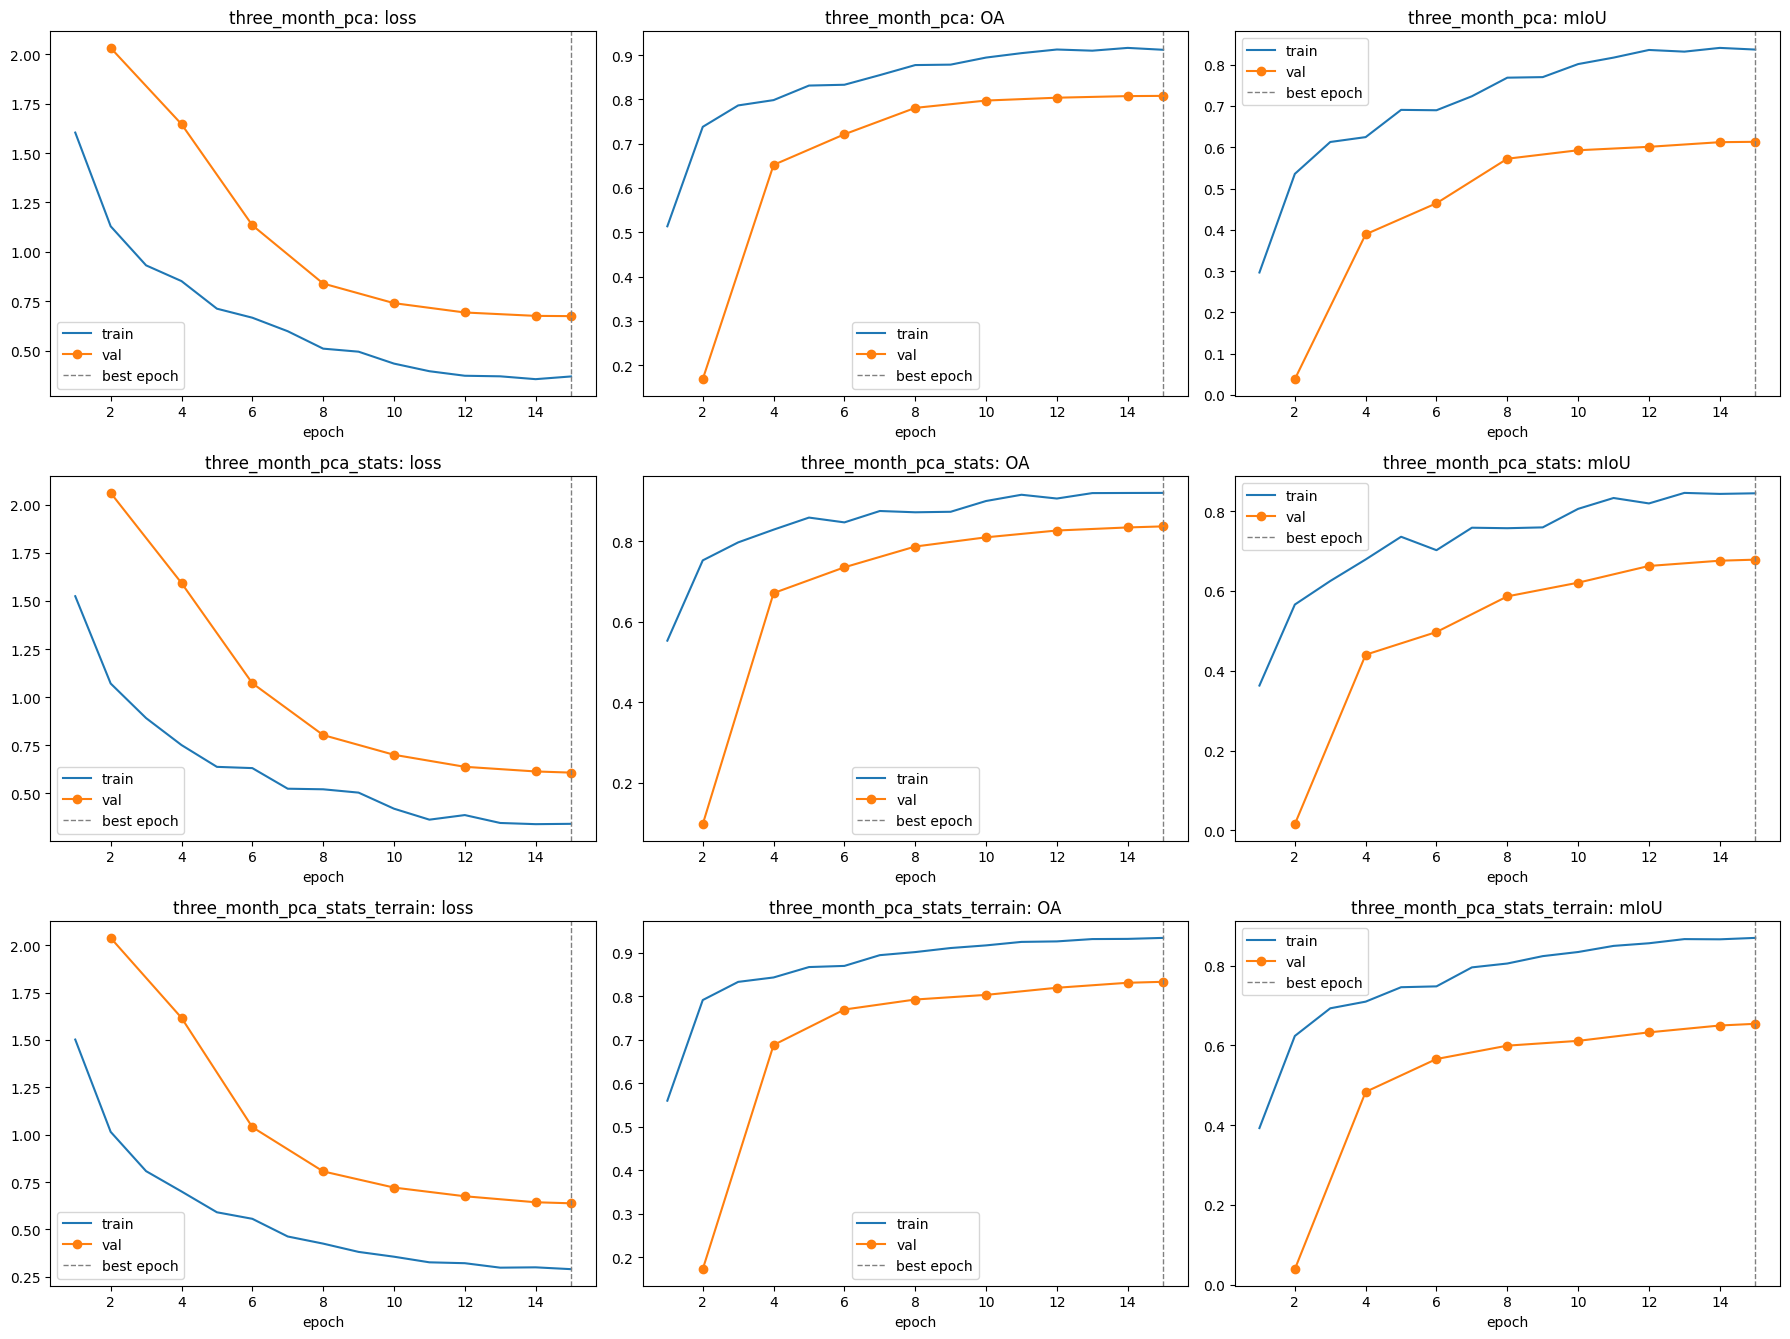

In [15]:
fig, axes = plt.subplots(len(histories), 3, figsize=(18, 4.5 * len(histories)), squeeze=False)
for row, (name, h) in enumerate(histories.items()):
    best_epoch = h.epoch[h.val_mIoU.idxmax()]
    v = h.dropna(subset=["val_mIoU"])
    for ax, metric in zip(axes[row], ["loss", "OA", "mIoU"]):
        ax.plot(h.epoch, h[f"train_{metric}"], label="train")
        ax.plot(v.epoch, v[f"val_{metric}"], marker="o", label="val")
        ax.axvline(best_epoch, color="grey", ls="--", lw=1, label="best epoch")
        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("epoch")
        ax.legend()
    gap = h.train_mIoU[h.val_mIoU.idxmax()] - h.val_mIoU.max()
    print(f"{name}: best epoch {best_epoch}, train-val mIoU gap at best epoch {gap:.3f} (baseline: 0.31)")
plt.tight_layout()
plt.savefig(OUT / "training_curves.png", dpi=120)
plt.show()

### 10.2 Test scores

The test set has 20 sites that were never used for training or model selection. Every test patch is evaluated with **all 12 months**. The test sites are the same as in the baseline run. The seasonal snow label fix added a few labelled test pixels (mainly Anchorage), so the comparison with the baseline is close but not exact.

In [16]:
BASELINE = {"OA": 0.8427, "mIoU": 0.5593}
results = {}
for name, variant in VARIANTS.items():
    test_dl = DataLoader(EvalDataset(X["test"], Y["test"], STATIC_X["test"], variant), 2 * BATCH,
                         num_workers=NUM_WORKERS, pin_memory=True)
    results[name] = evaluate(models[name], test_dl, per_month=True)

comparison = pd.DataFrame({name: {"OA": r["OA"], "mIoU": r["mIoU"],
                                  "mIoU vs baseline": r["mIoU"] - BASELINE["mIoU"],
                                  "best val mIoU": histories[name].val_mIoU.max(),
                                  "epochs": len(histories[name])}
                           for name, r in results.items()}).T
display(comparison.round(4))

per_class = pd.concat({name: pd.DataFrame({"IoU": r["IoU"], "F1": r["F1"]}, index=CLASS_NAMES)
                       for name, r in results.items()}, axis=1)
display(per_class.round(3))

BEST = comparison["best val mIoU"].idxmax()
print("best variant (chosen by val mIoU, test is only reported):", BEST)
json.dump({name: {"OA": r["OA"], "mIoU": r["mIoU"],
                  "IoU": dict(zip(CLASS_NAMES, r["IoU"].round(4).tolist())),
                  "F1": dict(zip(CLASS_NAMES, r["F1"].round(4).tolist())),
                  "month_mIoU": [round(v, 4) for v in r["month_mIoU"]]}
           for name, r in results.items()}, open(OUT / "test_metrics.json", "w"), indent=2)

,OA,mIoU,mIoU vs baseline,best val mIoU,epochs
three_month_pca,0.8779,0.6641,0.1048,0.6132,15.0
three_month_pca_stats,0.8391,0.5658,0.0065,0.6785,15.0
three_month_pca_stats_terrain,0.8318,0.5575,-0.0018,0.6543,15.0


three_month_pca        three_month_pca_stats         \
                               IoU     F1                   IoU     F1   
Built-up                     0.943  0.971                 0.944  0.971   
Cropland                     0.399  0.571                 0.461  0.631   
Trees                        0.660  0.796                 0.620  0.765   
Shrub & grass                0.482  0.651                 0.421  0.592   
Bare / sparse                0.725  0.841                 0.614  0.761   
Water                        0.631  0.774                 0.672  0.804   
Wetland & mangrove           0.780  0.877                 0.100  0.183   
Snow & ice                   0.689  0.816                 0.695  0.820   

                   three_month_pca_stats_terrain         
                                             IoU     F1  
Built-up                                   0.947  0.973  
Cropland                                   0.568  0.724  
Trees                                      0.606  0.755  
Shrub & grass                              0.305  0.468  
Bare / sparse                              0.357  0.526  
Water                                      0.490  0.658  
Wetland & mangrove                         0.570  0.726  
Snow & ice                                 0.617  0.763

best variant (chosen by val mIoU, test is only reported): three_month_pca_stats


### 10.3 Confusion matrix

Each **row** is a true class and each **column** a predicted class. The rows sum to 1, so the diagonal is the share of each class that was found (recall). Large off-diagonal values show which classes the radar confuses, for example trees vs cropland (both scatter in the vegetation volume) or water vs snow (both can be dark and smooth).

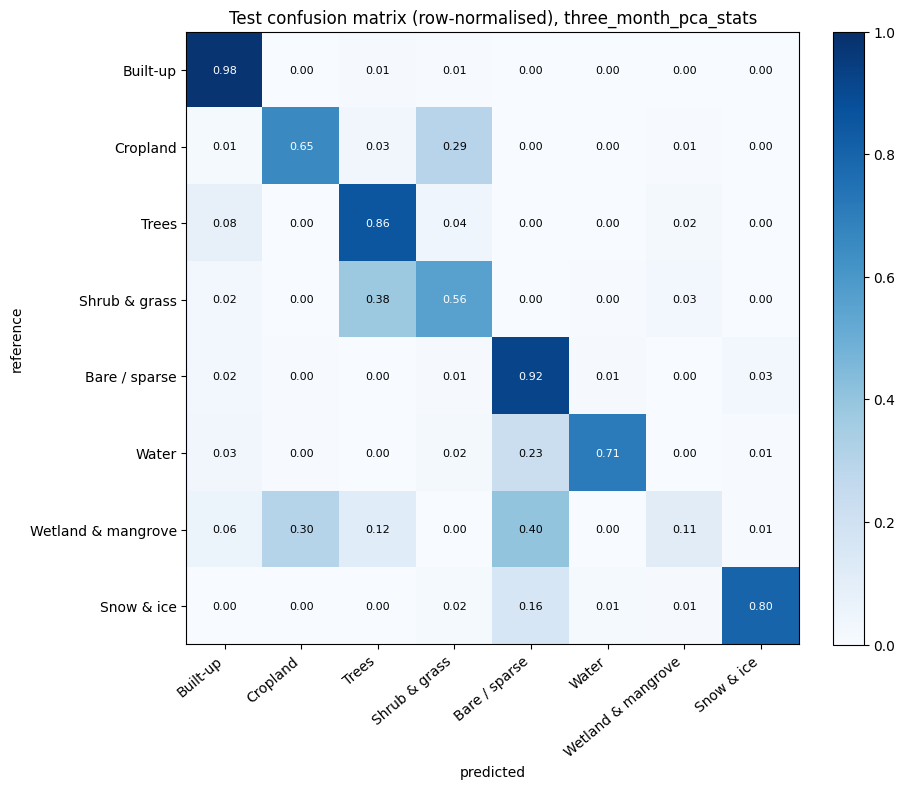

In [17]:
conf = results[BEST]["confusion"].astype(np.float64)
conf_norm = conf / conf.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(conf_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{conf_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if conf_norm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=40, ha="right")
ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("reference")
ax.set_title(f"Test confusion matrix (row-normalised), {BEST}")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=120)
plt.show()

### 10.4 Scores per region, site type and month

- **Per region** shows how well the model transfers to different parts of the world.
- **Per site type** groups the test sites by their dominant landscape. Read the OA column here: inside one site type the rare classes have few pixels, which makes mIoU unstable.
- **Per month** shows the **seasonal effect**. The label is the same all year, so a drop in some months means the radar signal changed (snow, frozen or wet soil, bare fields after harvest). In the prototype, such drops appear as fake land-cover change.

,patches,OA,mIoU
region,,,
africa,49,0.787,0.406
asia,109,0.907,0.595
europe,32,0.936,0.482
n_america,64,0.640,0.361
oceania,16,0.962,0.429
s_america,32,0.940,0.376


,patches,OA,mIoU
focus,,,
bare,16,1.000,1.000
cropland,17,0.704,0.364
shrub_grass,16,0.589,0.121
snow_ice,13,0.787,0.333
trees,16,0.949,0.261
urban,208,0.919,0.413
wetland,16,0.126,0.060


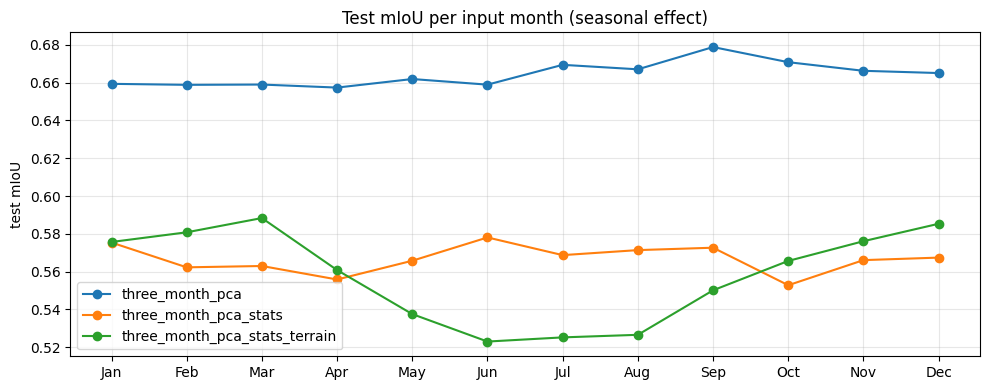

In [18]:
def group_scores(model, variant, column):
    rows = []
    for group, df in index["test"].groupby(column):
        ids = df.index.to_numpy()
        dl = DataLoader(EvalDataset(X["test"][ids], Y["test"][ids], STATIC_X["test"][ids], variant), 2 * BATCH, num_workers=NUM_WORKERS)
        r = evaluate(model, dl)
        rows.append({column: group, "patches": len(ids), "OA": r["OA"], "mIoU": r["mIoU"]})
    return pd.DataFrame(rows).set_index(column).round(3)


display(group_scores(models[BEST], VARIANTS[BEST], "region"))
display(group_scores(models[BEST], VARIANTS[BEST], "focus"))

plt.figure(figsize=(10, 4))
for name, r in results.items():
    plt.plot(MONTH_NAMES, r["month_mIoU"], marker="o", label=name)
plt.ylabel("test mIoU")
plt.title("Test mIoU per input month (seasonal effect)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "month_miou.png", dpi=120)
plt.show()

### 10.5 Example predictions on unseen test sites

One test patch per site type, predicted from the July composite. Black pixels in the reference are *ignore* (the label maps disagree); the model still predicts them.

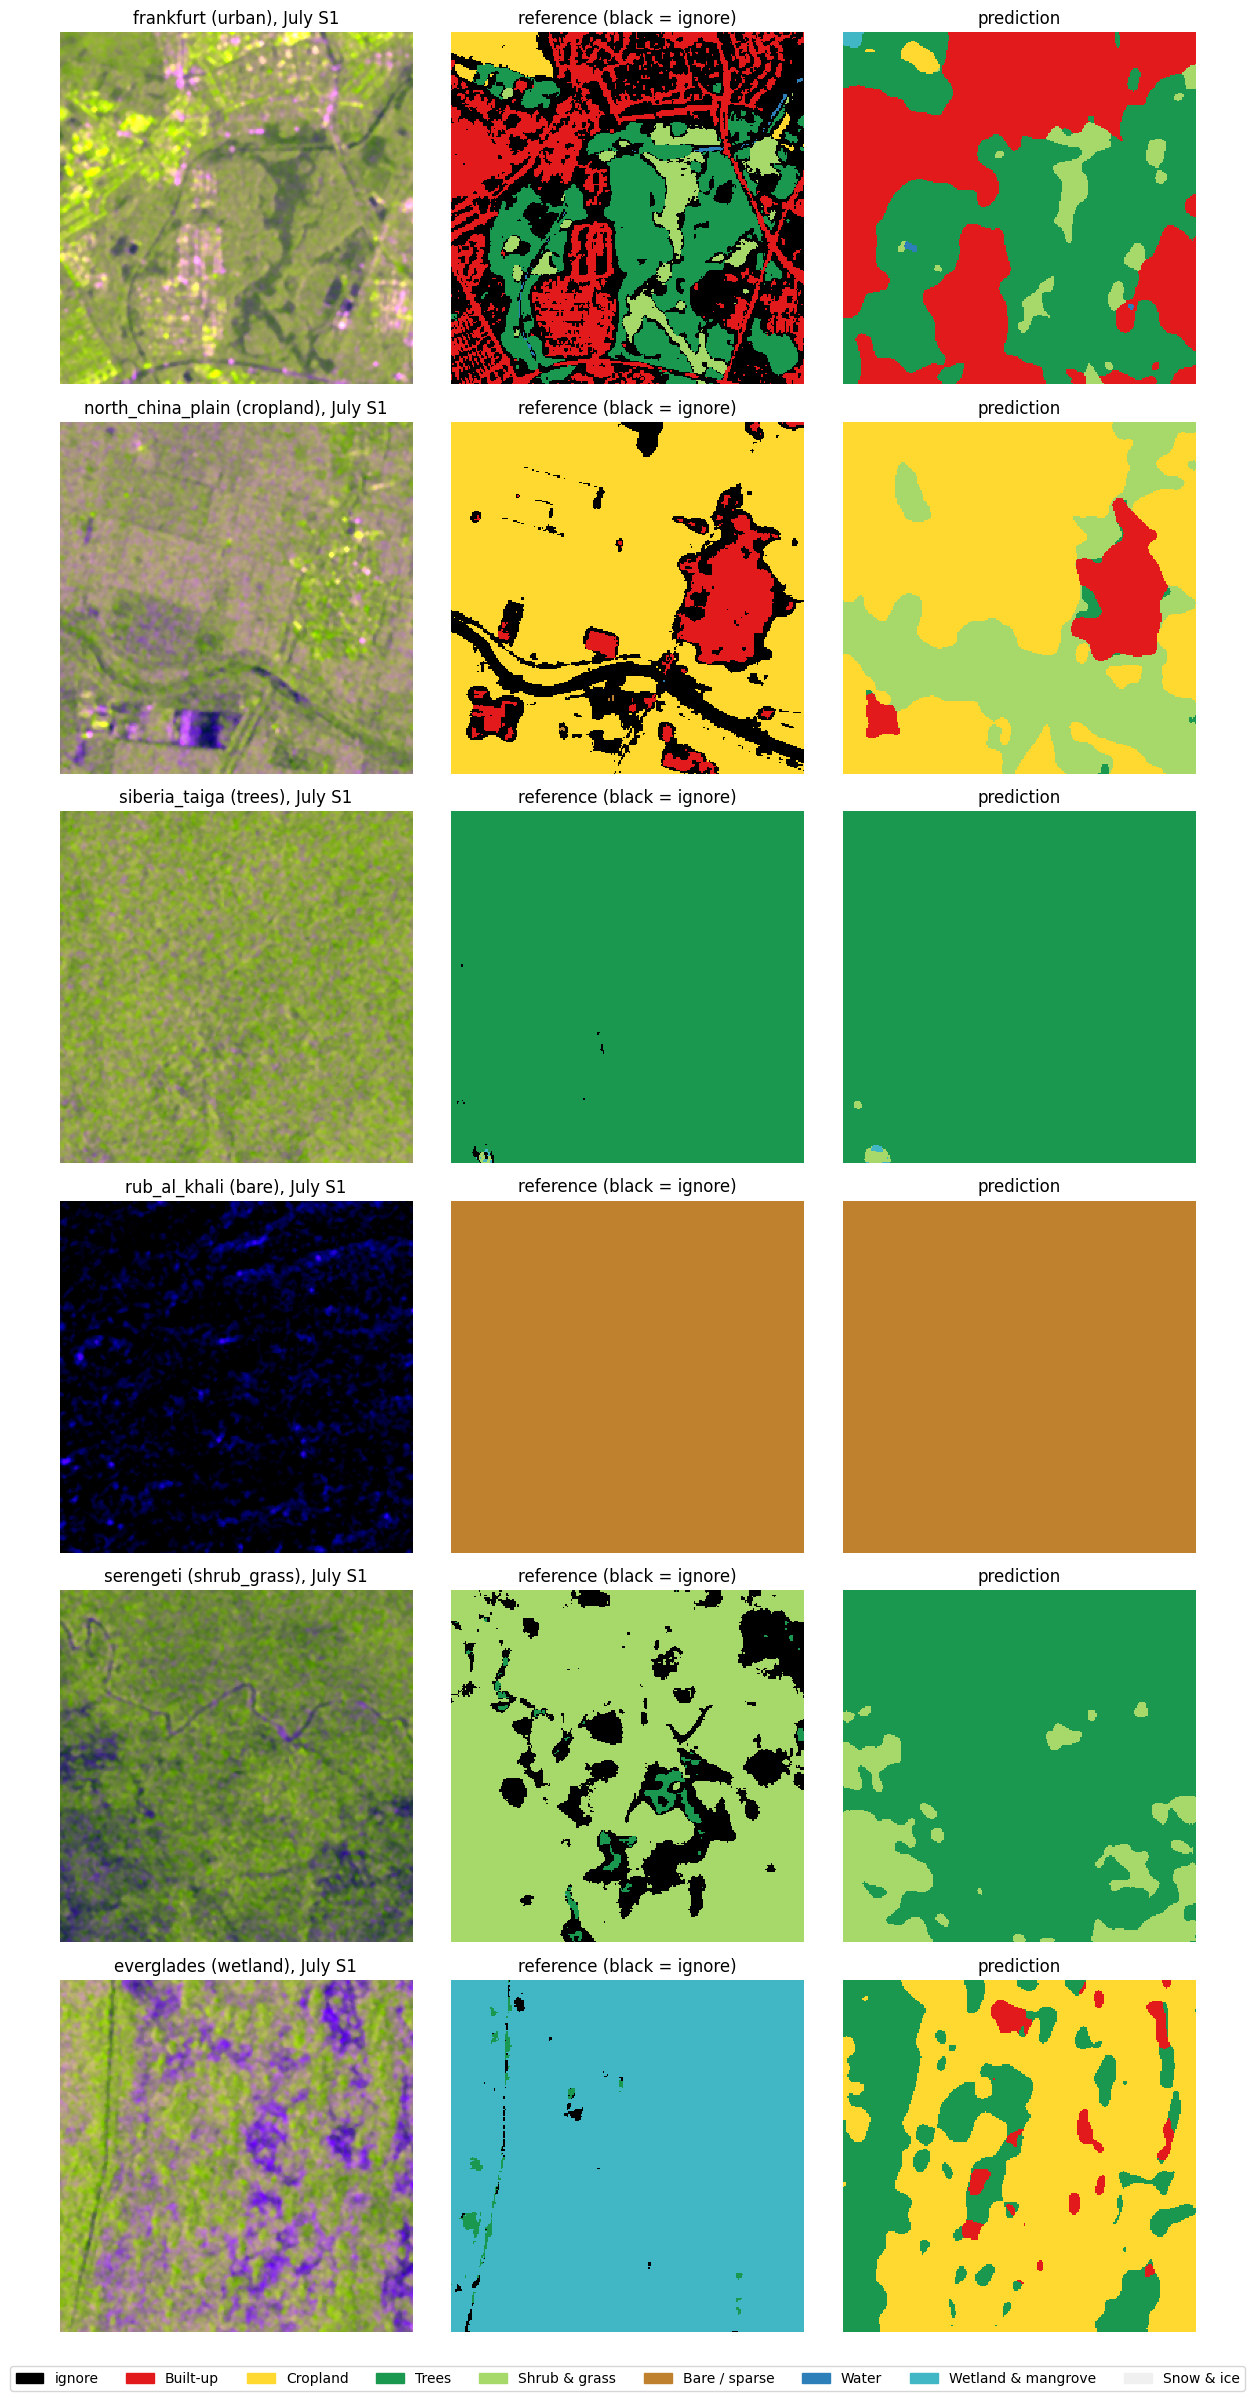

In [19]:
model = models[BEST].eval()
picks = [index["test"][index["test"].focus == f].index[0] for f in index["test"].focus.unique()][:6]
fig, axes = plt.subplots(len(picks), 3, figsize=(12, 4 * len(picks)))
for row, i in enumerate(picks):
    month = 6
    codes = torch.from_numpy(window_codes(X["test"][i], month, VARIANTS[BEST]))[None]
    static = torch.from_numpy(STATIC_X["test"][i][static_index(VARIANTS[BEST])])[None]
    with torch.no_grad():
        pred = model(gpu_input(codes, static)).argmax(1)[0].cpu().numpy()
    axes[row, 0].imshow(false_colour(X["test"][i, month]))
    axes[row, 0].set_title(f"{index['test'].site[i]} ({index['test'].focus[i]}), July S1")
    axes[row, 1].imshow(Y["test"][i] + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[row, 1].set_title("reference (black = ignore)")
    axes[row, 2].imshow(pred + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[row, 2].set_title("prediction")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=9)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(OUT / "example_predictions.png", dpi=110)
plt.show()

## 11. Export for the prototype

The best model's weights are saved with everything the prototype needs to reproduce the preprocessing exactly:
- the channels, the number of months and the month-window rule;
- the normalisation statistics;
- the PCA mean and projection matrix, and the definitions and normalisation of the seasonal statistics and terrain channels (each used only if the best variant has them);
- the uint8 decoding, class names and colours.

In [20]:
model_card = {
    "variant": BEST,
    "n_months": VARIANTS[BEST]["n_months"],
    "pca": VARIANTS[BEST]["pca"],
    "stats": VARIANTS[BEST]["stats"],
    "terrain": VARIANTS[BEST]["terrain"],
    "static_channels": [STATIC_NAMES[k] for k in static_index(VARIANTS[BEST])],
    "channel_order": "monthly channels (oldest month first), then static_channels",
    "in_channels": input_channels(VARIANTS[BEST]),
    "channels_per_month": ["VV_dB", "VH_dB", "VV_minus_VH_dB"],
    "month_window": "target month and the previous n_months-1 months, oldest first",
    "pca_input": "36 standardised values per pixel (Jan..Dec x VV, VH, VV-VH), ordered by calendar month; "
                 "components = pca_weights @ (values - pca_mean)",
    "channel_mean": CH_MEAN.tolist(),
    "channel_std": CH_STD.tolist(),
    "pca_mean": PCA_MEAN.tolist(),
    "pca_weights": PCA_W.tolist(),
    "stats_definition": "over the 12 months in dB: VV min, VV max, VH std, VH 2nd highest - 2nd lowest, "
                        f"share of valid months with VV < {WATER_DB} dB; standardised with stats_mean/std",
    "stats_mean": STAT_MEAN.tolist(),
    "stats_std": STAT_STD.tolist(),
    "terrain_definition": "Copernicus GLO-30 elevation (m), slope (deg), log1p(MERIT Hydro HAND in m); "
                          "standardised with terrain_mean/std",
    "terrain_mean": TER_MEAN.tolist(),
    "terrain_std": TER_STD.tolist(),
    "ema_decay": EMA_DECAY,
    "nan_fill_after_standardisation": 0.0,
    "db_decoding": {"db_min": DB_MIN, "db_step": DB_STEP, "nodata_code": 0},
    "class_names": CLASS_NAMES,
    "class_colors": CLASS_COLORS,
    "patch_size": PATCH,
    "architecture": "UNetResNet34 (this notebook)",
    "weights": f"{BEST}_best.pt",
    "test_OA": results[BEST]["OA"],
    "test_mIoU": results[BEST]["mIoU"],
}
json.dump(model_card, open(OUT / "model_card.json", "w"), indent=2)
print({k: v for k, v in model_card.items() if k not in ("pca_mean", "pca_weights", "stats_mean", "stats_std")})
print(sorted(p.name for p in OUT.iterdir()))

{'variant': 'three_month_pca_stats', 'n_months': 3, 'pca': True, 'stats': True, 'terrain': False, 'static_channels': ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'VV min', 'VV max', 'VH std', 'VH spread', 'water months'], 'channel_order': 'monthly channels (oldest month first), then static_channels', 'in_channels': 20, 'channels_per_month': ['VV_dB', 'VH_dB', 'VV_minus_VH_dB'], 'month_window': 'target month and the previous n_months-1 months, oldest first', 'pca_input': '36 standardised values per pixel (Jan..Dec x VV, VH, VV-VH), ordered by calendar month; components = pca_weights @ (values - pca_mean)', 'channel_mean': [-9.18918514251709, -16.590747833251953, 7.40156364440918], 'channel_std': [5.639369487762451, 5.735973834991455, 2.727762222290039], 'stats_definition': 'over the 12 months in dB: VV min, VV max, VH std, VH 2nd highest - 2nd lowest, share of valid months with VV < -18.0 dB; standardised with stats_mean/std', 'terrain_definition': 'Copernicus GLO-30 elevation (m), slope 

## 12. Save the run

Everything above is already written to `Weights/<RUN_NAME>/`. The best weights are saved at every improvement, so a crash keeps the last best. This cell saves the final weights and histories once more and zips the folder, so the whole run is one download from Kaggle's **Output** tab. Only committed runs (**Save Version → Save & Run All**) keep their output.

In [21]:
for name in models:
    torch.save(models[name].state_dict(), OUT / f"{name}_best.pt")
    histories[name].to_csv(OUT / f"{name}_history.csv", index=False)
archive = shutil.make_archive(str(OUT), "zip", OUT)
print("saved:", sorted(p.name for p in OUT.iterdir()))
print("archive:", archive)


saved: ['confusion_matrix.png', 'example_predictions.png', 'model_card.json', 'month_miou.png', 'test_metrics.json', 'three_month_pca_best.pt', 'three_month_pca_history.csv', 'three_month_pca_stats_best.pt', 'three_month_pca_stats_history.csv', 'three_month_pca_stats_terrain_best.pt', 'three_month_pca_stats_terrain_history.csv', 'training_curves.png']
archive: /home/jovyan/vault/LULC-semantic-Model/Weights/Test_4.zip
